<div style="border-left:5px solid #67CBEE;padding:10px 16px;background:#F7F9FB;color:#19222D;margin:12px 0"><b>AMD Radeon · YOLO26 · Day 01</b><br><span style="color:#536273">算法 → 数据 → 训练 → 评测 → 证据。每一个结论都应由实际运行结果支撑。</span><br><span style="color:#536273">Algorithm → Data → Training → Evaluation → Evidence. Every conclusion must be backed by real execution results.</span></div>

# 02 / Lab B · 数据集、标注、分离与 QA

**建议时长：50–60 分钟**　｜　学习路径：手工标注 → 导出 → 防泄漏划分 → QA

> 请按顺序运行；运行结果必须来自自己的 GPU 环境，不可把示例文字当作实测数据。

---

# 02 / Lab B · Dataset, Annotation, Splits & QA

**Suggested time: 50–60 minutes** | Learning path: manual labeling → export → grouped splits → QA

> Run the cells in order; every result must come from your own GPU environment — never present the sample text as measured data.

### 学习地图（30 秒看完这张表再开始）

| 问题 | 答案 |
|---|---|
| 为什么学这个？ | 真实项目约七成时间在数据；脏数据与泄漏是"成绩造假"的头号来源 |
| 需要先懂什么？ | 完成 00；课前装好 X-AnyLabeling 并标注 ≥5 张（见 `docs/LAB_B_X_ANYLABELING.md`） |
| 我修改哪个参数？ | 修正练习的 `NEW_LABEL_LINE`/`LABEL_LINE_INDEX`（须显式 `APPLY_CORRECTION=True` 才写入） |
| 成功长什么样？ | QA `pass=true`、标注画廊带框、无效标签注入实验会报错 |
| 失败怎么自救？ | 本页常见错误表；导入器报错精确到文件与行 |
| 保存什么证据？ | data.yaml、QA JSON、split_manifest.csv、人工检查表 |
| 求职价值？ | 数据岗必问："你怎么发现训练/测试泄漏？"——这节就是标准答案 |

---

### Lab Map (read this 30-second table first)

| Question | Answer |
|---|---|
| Why learn this? | Real projects spend ~70% of time on data; dirty data and leakage are the top sources of fake scores |
| Prerequisites? | Lab 00; X-AnyLabeling installed and ≥5 images labeled before class (see `docs/LAB_B_X_ANYLABELING.md`) |
| What do I change? | `NEW_LABEL_LINE`/`LABEL_LINE_INDEX` in the correction exercise (writes only with an explicit `APPLY_CORRECTION=True`) |
| What does success look like? | QA `pass=true`, a labeled gallery, and the injected-invalid-label experiment raising errors |
| If it falls? | The common-errors table on this page; importer errors name the exact file and line |
| Evidence to save? | data.yaml, the QA JSON, split_manifest.csv, the manual review sheet |
| Job value? | Data-role staple: "How would you catch train/test leakage?" — this lab is the answer |

## 实验目标
- 检查一行 YOLO 标签 `class x_center y_center width height`，五个值中坐标为归一化值。
- 从 COCO128 **原始 128 张图**构造教学用、图片不重叠的 Train/Val/Test；默认只保留 `person/car/chair` 三类，并**不是**快递包裹数据集。
- 检查标签范围、重复图片、边界框与数据集配置。

**依赖**：先完成 00（环境与权重缓存）。本实验主要用 CPU 做数据 QA，不需要长时间占用 GPU。

> **关键科学边界**：官方 COCO128 训练/验证复用同样图片，仅用于冒烟测试。本 Notebook 对其重新分组和划分，尽量防止直接重叠；由于只有 128 张，无法据此宣称工业精度或严格 COCO 基准；语义相似场景泄漏还需人工审查。

---

## Goal
- Parse one YOLO label line `class x_center y_center width height`; the four coordinates are normalized.
- Build a teaching-only, image-disjoint Train/Val/Test from the **original 128 COCO128 images**, keeping only `person/car/chair` — this is **not** a parcel dataset.
- Check label ranges, duplicates, bounding boxes and the dataset config.

> **Key scientific boundary**: official COCO128 reuses the same images for train and val and is for smoke tests only. This notebook re-groups and re-splits them to prevent direct overlap; with just 128 images the result can never be presented as industrial accuracy or a strict COCO benchmark, and semantically similar scenes still need human review.

### 常见错误与下一步
| 症状 | 原因 | 下一步 |
|---|---|---|
| `Scene CSV must cover every image exactly once` | scenes.csv 漏图/多图/文件名对不上 | 按报错里的 missing/extra 清单逐个核对文件名（区分大小写） |
| `Invalid YOLO detection labels ... invalid class id` | 类别号 ≥ classes.txt 行数 | 类别 ID 从 0 开始且小于类别数；检查 X-AnyLabeling 导出时的类别顺序 |
| `Missing labels: [...]` | 有图片但没有对应 txt | 为确认无目标的图片创建**空** txt（合法负样本），不要删图 |
| `FileExistsError ... choose a new output name` | 同名数据集已导入过 | 换 `YOLO_ANYLABELING_OUTPUT_NAME`（如 `_v2`），不要删除旧结果 |
| `At least 9 images` / `Fewer than three independent groups` | 样本或独立场景太少 | 课上先用 COCO128 演示路径完成教学目标，课后补数据再导入 |

---

### Common Errors & Next Steps
| Symptom | Cause | Next step |
|---|---|---|
| `Scene CSV must cover every image exactly once` | scenes.csv missing/extra/mismatched names | Fix filenames one by one using the missing/extra lists in the error (case-sensitive) |
| `Invalid YOLO detection labels ... invalid class id` | class id ≥ number of classes.txt lines | Class IDs are zero-based; check the class order in the X-AnyLabeling export |
| `Missing labels: [...]` | image without a matching txt | Create an **empty** txt for verified negatives — never delete the image |
| `FileExistsError ... choose a new output name` | dataset name already imported | Change `YOLO_ANYLABELING_OUTPUT_NAME` (e.g. `_v2`); never delete the old result |
| `At least 9 images` / `Fewer than three independent groups` | too few samples or scenes | Use the COCO128 demo path in class; collect more data and re-import after class |

### 新的 Lab B：先手工标注，再自动检查
1. 在 Windows/macOS/Linux 本地安装开源 **X-AnyLabeling**（它是独立桌面软件，不要装进 ROCm PyTorch 环境）。
2. 讲师提供已获授权的图片；每名学生先手工绘制至少 5 张图片的矩形框，与同伴交换至少 5 张进行复核。先定义统一的类别顺序：classes.txt 每行一个类别，从 0 开始。
3. 在 X-AnyLabeling 选择 **Export Annotations → Export YOLO Annotations → Detection**，使用 classes.txt，得到按图片名称对应的 YOLO 检测 txt；图片保存在 images/，导出标签放在独立的 labels/ 文件夹。
4. 上传 images/、labels/、classes.txt 至 Radeon Cloud，默认示例目录：/workspace/yolo_course/data/raw/anylabeling/。**先通过人工审核并确认版权/使用权限，再进行导入**。
5. 在下面设置 YOLO_ANYLABELING_EXPORT（可设置环境变量或直接修改代码变量）。只读源文件，另建数据集并生成 train/val/test、split_manifest.csv、data.yaml、QA 报告。已有输出不会被覆盖。
6. 同一视频、同一场景、近重复图片不能跨集合。推荐提供 scenes.csv 两列 image,scene；没有此文件时只执行图像相似性启发式分组，仍需人工检查。

**教学注意**：至少需要 9 张图和 3 个独立场景/图片组；不足时继续用 COCO128 安全演示，不能把无效小数据集伪装成可泛化训练集。导入成功后 Lab C 自动读取新 data.yaml。未提供导出则保留原先 COCO128 默认路径。

---

### Updated Lab B: annotate by hand, then validate
1. Install the free, open-source **X-AnyLabeling** desktop app outside your ROCm Python environment.
2. Annotate at least five licensed images per student with rectangle boxes; cross-review at least five images with a teammate. Define the shared class order using classes.txt (one nonempty name per line, zero-based IDs).
3. Use **Export Annotations → Export YOLO Annotations → Detection** and classes.txt. Keep images/ and exported labels/ separate, with matching image/label stems.
4. Upload images/, labels/, classes.txt to Radeon Cloud (example /workspace/yolo_course/data/raw/anylabeling/) after manual review and permission checks.
5. Set YOLO_ANYLABELING_EXPORT to the export folder. The importer never edits sources; it creates a new train/val/test dataset, manifest, data.yaml and QA report. Existing output is never overwritten.
6. Group images from the same video/scene before splitting. Provide optional scenes.csv with image,scene columns; without it the perceptual duplicate heuristic still requires human review.

**Teaching boundary**: at least nine images and three independent groups are required. Otherwise use the default COCO128 demo. A tiny dataset does not establish industrial generalization. Lab C reuses the successful import via shared config.

In [1]:
from pathlib import Path
import os
import sys
import json

candidates = [Path.cwd(), Path.cwd().parent, Path('/workspace/YOLO26_ROCm_Day1_Labs')]
package = next((p for p in candidates if (p / 'course/lab_utils.py').exists()), None)
if package is None:
    raise FileNotFoundError('请先将 ZIP 完整解压，并从项目目录或 notebooks/ 目录启动 Jupyter。')
sys.path.insert(0, str(package))
from course.lab_utils import (root, ensure_dirs, load_config, save_config, write_json,
                              write_csv, system_info, require_rocm, sha256)

home = ensure_dirs()
cfg = load_config()
print('Project:', package, '\nPersistent output:', home)

Project: /workspace/yolo26-rocm-day1-labs 
Persistent output: /workspace/yolo_course_release_fixture


In [2]:
from course.lab_utils import (download_coco128,prepare_coco128_demo,inspect_dataset,
    plot_labels,read_labels,label_errors,list_images)
from course.annotation_import import import_anylabeling_yolo
from IPython.display import display
from matplotlib import pyplot as plt

# Option 1: a pre-split and independently reviewed user dataset
USER_DATA_YAML = os.environ.get('YOLO_USER_DATA_YAML', '').strip()

# Option 2: X-AnyLabeling export: images/, labels/, classes.txt
# Example: /workspace/yolo_course/data/raw/anylabeling
YOLO_ANYLABELING_EXPORT = os.environ.get('YOLO_ANYLABELING_EXPORT', '').strip()
YOLO_ANYLABELING_SCENES = os.environ.get('YOLO_ANYLABELING_SCENES', '').strip()
YOLO_ANYLABELING_OUTPUT_NAME = os.environ.get('YOLO_ANYLABELING_OUTPUT_NAME',
                                                'xanylabeling_student_v1').strip()
if USER_DATA_YAML:
    yaml_path=Path(USER_DATA_YAML).expanduser().resolve()
    if not yaml_path.is_file(): raise FileNotFoundError(yaml_path)
    save_config({'dataset_yaml':str(yaml_path),'dataset_kind':'user_provided'})
    print('Using user-owned dataset:',yaml_path)
elif YOLO_ANYLABELING_EXPORT:
    export=Path(YOLO_ANYLABELING_EXPORT).expanduser().resolve()
    dest=home/'data/processed'/YOLO_ANYLABELING_OUTPUT_NAME
    assert YOLO_ANYLABELING_OUTPUT_NAME and Path(YOLO_ANYLABELING_OUTPUT_NAME).name == YOLO_ANYLABELING_OUTPUT_NAME
    if dest.exists():
        if not (dest/'data.yaml').is_file():
            raise FileExistsError(f'Destination already exists; choose a new output name: {dest}')
        print('Using previously imported dataset; change YOLO_ANYLABELING_OUTPUT_NAME for a new revision:',dest)
    else:
        imported=import_anylabeling_yolo(
            export/'images', export/'labels', export/'classes.txt', dest,
            scene_csv=Path(YOLO_ANYLABELING_SCENES) if YOLO_ANYLABELING_SCENES else None,
            seed=42)
        write_json(home/'reports/lab_b_annotation_import.json',imported)
        print('X-AnyLabeling export imported:',imported)
    yaml_path=dest/'data.yaml'
    save_config({'dataset_yaml':str(yaml_path),
                 'dataset_kind':'X-AnyLabeling_student_reviewed_teaching'})
else:
    # Validated fallback: COCO128 with regrouping, 3 selected COCO categories.
    source=download_coco128(home)
    dest=home/'data/processed/coco128_classroom_3class'
    if (dest/'data.yaml').is_file():
        print('Reusing existing dataset; do not overwrite student corrections automatically.')
    else:
        report=prepare_coco128_demo(source,dest,seed=42)
        print(report)
    yaml_path=dest/'data.yaml'
    save_config({'dataset_yaml':str(yaml_path),'dataset_kind':'COCO128_repartitioned_teaching_only'})
print('Training dataset:',yaml_path)

X-AnyLabeling export imported: {'dataset_kind': 'X-AnyLabeling YOLO detection export', 'source_images': '/workspace/fixture_xanylabeling_export/images', 'source_labels': '/workspace/fixture_xanylabeling_export/labels', 'source_classes': '/workspace/fixture_xanylabeling_export/classes.txt', 'scene_csv': '/workspace/fixture_xanylabeling_export/scenes.csv', 'images': 32, 'boxes': 94, 'classes': ['person', 'car', 'chair'], 'split_counts': {'train': 22, 'val': 5, 'test': 5}, 'independent_groups': 6, 'seed': 42, 'data_yaml': '/workspace/yolo_course_release_fixture/data/processed/xanylabeling_fixture_v1/data.yaml', 'limits': 'Small classroom split, not an industrial benchmark; humans must review scene similarity.', 'qa_warnings': []}
Training dataset: /workspace/yolo_course_release_fixture/data/processed/xanylabeling_fixture_v1/data.yaml


In [3]:
qa = inspect_dataset(yaml_path)
print('Class names:', qa['names'])
print('Split stats:', qa['splits'])
print('Errors:', qa['problems'][:30])
print('Near-duplicate review warnings:', qa['warnings'][:10])
write_json(home / 'reports/lab_b_dataset_qa.json',
           {k: v for k, v in qa.items() if k != 'sample_paths'})
assert qa['pass'], '发现数据结构错误，请先修复再训练'
print('Dataset structural QA: PASS')

Class names: {0: 'person', 1: 'car', 2: 'chair'}
Split stats: {'train': {'images': 22, 'boxes': 46, 'empty_or_missing_labels': 10}, 'val': {'images': 5, 'boxes': 2, 'empty_or_missing_labels': 3}, 'test': {'images': 5, 'boxes': 46, 'empty_or_missing_labels': 1}}
Errors: []
Near-duplicate review warnings: []
Dataset structural QA: PASS


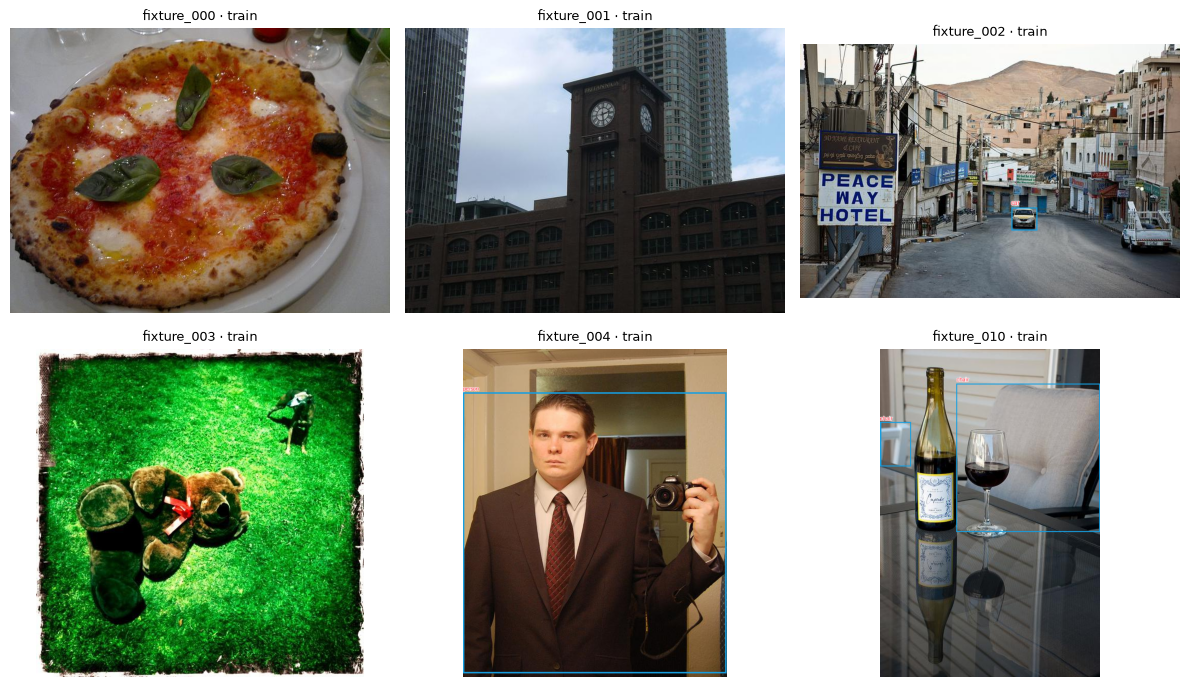

In [4]:
# 可视化训练标签；此步骤由学生人工复核遮挡、错标、漏标等问题
names = list(qa['names'].values()) if isinstance(qa['names'], dict) else list(qa['names'])
train_imgs = qa['sample_paths']['train']
fig = plot_labels(train_imgs, names, 6)
fig.savefig(home / 'assets/lab_b_label_gallery.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# 代码练习：验证无效标签能够被 QA 捕获，不会污染实际数据集
valid = '0 0.5 0.5 0.2 0.3\n'
invalid = '0 1.2 0.5 0.2 0.3\n'
assert not label_errors(valid, len(names))
assert label_errors(invalid, len(names))
print('Label format & invalid-bound tests: PASS')

Label format & invalid-bound tests: PASS


In [6]:
# 创建人工审阅清单。不要直接上传敏感/受限图像到公开 GitHub。
review=[{'image':str(img),'label':str(Path(qa['root'])/'labels/train'/f'{img.stem}.txt'),
         'approved':'', 'issue_type':'', 'corrected':'', 'note':''} for img in train_imgs[:20]]
review_path=home/'reports/lab_b_manual_review.csv'
if review_path.exists():
    print('复用已填写的人工检查表，避免重复运行时覆盖:',review_path)
else:
    write_csv(review_path,review,
              ['image','label','approved','issue_type','corrected','note'])
    print('人工检查图片后填写:',review_path)

人工检查图片后填写: /workspace/yolo_course_release_fixture/reports/lab_b_manual_review.csv


### 标注修改实操：可审计，默认不写入
选择一张标注图片和其中一行，将新的标签行填写在下面；只有显式设置 `APPLY_CORRECTION=True` 时才会写入，且先备份旧标签。**请先核对人工真值，不可因为预测结果不合预期就任意修改真值标签。**

---

### Hands-on Annotation Correction: auditable, off by default
Pick an annotated image and one label line, then type the corrected line below. Nothing is written unless you explicitly set `APPLY_CORRECTION=True`, and the old label is always backed up first. **Verify against human ground truth first — never bend the truth labels just because predictions disappoint you.**

In [7]:
from course.lab_utils import label_path_for_image
import datetime

TARGET_IMAGE = train_imgs[0]
LABEL_LINE_INDEX = 0  # 一行一个目标，从 0 开始
NEW_LABEL_LINE = '0 0.500000 0.500000 0.200000 0.200000'  # 教学占位，不应盲目写入
CORRECTION_REASON = 'TODO: 请写清楚人工审核依据'
APPLY_CORRECTION = False  # 先通过可视化核对，再显式设为 True

label_file = label_path_for_image(TARGET_IMAGE)
original_lines = label_file.read_text(encoding='utf-8').splitlines()
print('编辑目标:', label_file)
print('原始标签:', original_lines[:3])

if APPLY_CORRECTION:
    assert CORRECTION_REASON and not CORRECTION_REASON.startswith('TODO:')
    assert 0 <= LABEL_LINE_INDEX < len(original_lines), '该图可能是合法的空标签，需要先选择有框的图片'
    assert not label_errors(NEW_LABEL_LINE, len(names))
    old_line = original_lines[LABEL_LINE_INDEX]
    backup = (home / 'artifacts/label_backups' /
              f'{label_file.stem}_'
              f'{datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")}.txt')
    backup.parent.mkdir(parents=True, exist_ok=True)
    backup.write_text(label_file.read_text(encoding='utf-8'), encoding='utf-8')
    original_lines[LABEL_LINE_INDEX] = NEW_LABEL_LINE
    label_file.write_text('\n'.join(original_lines) + '\n', encoding='utf-8')
    write_json(home / 'reports/lab_b_last_correction.json',
               {'image': str(TARGET_IMAGE), 'label': str(label_file),
                'before': old_line, 'after': NEW_LABEL_LINE,
                'reason': CORRECTION_REASON, 'backup': str(backup)})
    assert inspect_dataset(yaml_path)['pass'], '修改后数据集 QA 失败，请恢复备份'
    print('修正已写入，备份：', backup)
else:
    print('安全预览：未修改任何文件。')

编辑目标: /workspace/yolo_course_release_fixture/data/processed/xanylabeling_fixture_v1/labels/train/fixture_000.txt
原始标签: []
安全预览：未修改任何文件。


### 思考题 / 面试必答
1. 为什么 Train/Val/Test 必须隔离？同一视频相邻帧能否分到不同集合？
2. 标签缺失与空标签有何区别？哪些空标签是合理的负样本？
3. 为什么 COCO128 不能直接用于可信的模型排行榜成绩？
4. 哪些错误属于标注规范问题而非模型算法问题？

**交付**：`data/processed/.../data.yaml`、`split_manifest.csv`、`dataset_manifest.json`、QA JSON、人工检查表、标注图。

---

### Think / Interview Questions
1. Why must Train/Val/Test stay isolated? May adjacent frames of one video land in different splits?
2. Missing label file vs empty label — what is the difference? Which empty labels are legitimate negatives?
3. Why can't COCO128 directly produce trustworthy leaderboard scores?
4. Which errors are annotation-spec problems rather than model problems?

**Deliverables**: `data/processed/.../data.yaml`, `split_manifest.csv`, `dataset_manifest.json`, the QA JSON, the manual review sheet, annotated images.